In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import sklearn
import json
import os
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.svm import LinearSVC
from sklearn.metrics import classification_report, accuracy_score
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
import seaborn as sns

In [3]:
reddit_datasets = {
    'addiction': pd.read_csv('addiction_2019_features_tfidf_256.csv'),
    'adhd': pd.read_csv('adhd_2019_features_tfidf_256.csv'),
    'alcoholism': pd.read_csv('alcoholism_2019_features_tfidf_256.csv'),
    'anxiety': pd.read_csv('anxiety_2019_features_tfidf_256.csv'),
    'jokes': pd.read_csv('jokes_2019_features_tfidf_256.csv'),
    'mentalhealth': pd.read_csv('mentalhealth_2019_features_tfidf_256.csv'),
    'conspiracy': pd.read_csv('conspiracy_2019_features_tfidf_256.csv'),
    'fitness': pd.read_csv('fitness_2019_features_tfidf_256.csv'),
    'meditation': pd.read_csv('meditation_2019_features_tfidf_256.csv'),
    'relationship': pd.read_csv('relationships_2019_features_tfidf_256.csv'),
    'teaching': pd.read_csv('teaching_2019_features_tfidf_256.csv'),
    'suicidewatch': pd.read_csv('suicidewatch_2019_features_tfidf_256.csv'),
}

for name, df in reddit_datasets.items():
    df['subreddit_name'] = name

combined_df = pd.concat(reddit_datasets.values(), ignore_index=True)


In [4]:
print(combined_df.columns)


Index(['subreddit', 'author', 'date', 'post', 'automated_readability_index',
       'coleman_liau_index', 'flesch_kincaid_grade_level',
       'flesch_reading_ease', 'gulpease_index', 'gunning_fog_index',
       ...
       'tfidf_without', 'tfidf_wonder', 'tfidf_work', 'tfidf_worri',
       'tfidf_wors', 'tfidf_would', 'tfidf_wrong', 'tfidf_x200b', 'tfidf_year',
       'subreddit_name'],
      dtype='object', length=351)


Fitting 5 folds for each of 16 candidates, totalling 80 fits

Best Parameters: {'C': 1, 'class_weight': None, 'max_iter': 2000}
Test Accuracy: 0.9391

Classification Report:
               precision    recall  f1-score   support

           0       0.95      0.96      0.96     16982
           1       0.92      0.89      0.90      7907

    accuracy                           0.94     24889
   macro avg       0.93      0.93      0.93     24889
weighted avg       0.94      0.94      0.94     24889



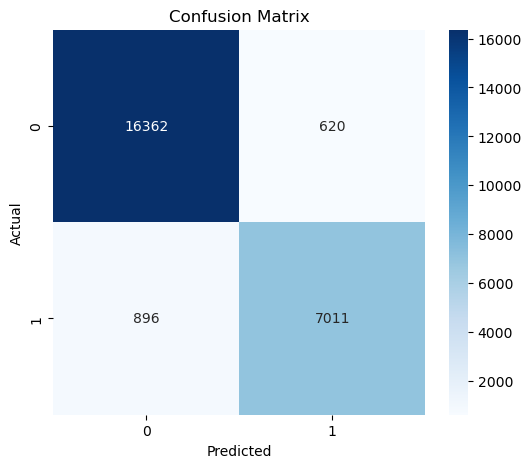

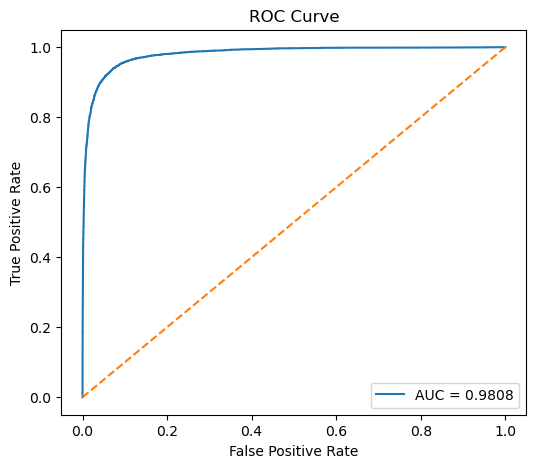

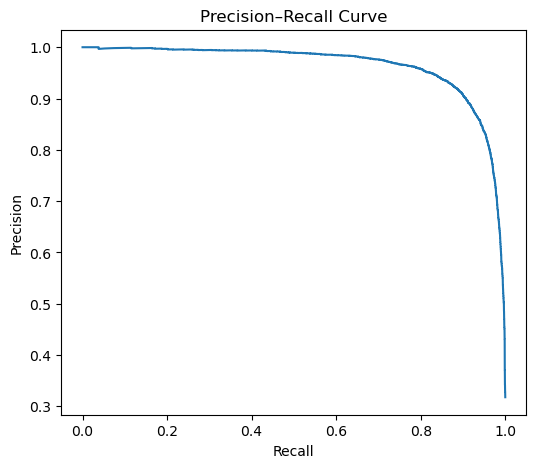

In [11]:
import pandas as pd
import json
import joblib
import matplotlib.pyplot as plt
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.svm import LinearSVC
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.metrics import (
    accuracy_score, 
    classification_report,
    confusion_matrix,
    roc_curve,
    auc,
    precision_recall_curve
)
import seaborn as sns
import numpy as np

# -------------------------------------------------------
# 1. LOAD DATA
# -------------------------------------------------------

reddit_datasets = {
    'addiction': pd.read_csv('addiction_2019_features_tfidf_256.csv'),
    'adhd': pd.read_csv('adhd_2019_features_tfidf_256.csv'),
    'alcoholism': pd.read_csv('alcoholism_2019_features_tfidf_256.csv'),
    'anxiety': pd.read_csv('anxiety_2019_features_tfidf_256.csv'),
    'jokes': pd.read_csv('jokes_2019_features_tfidf_256.csv'),
    'mentalhealth': pd.read_csv('mentalhealth_2019_features_tfidf_256.csv'),
    'conspiracy': pd.read_csv('conspiracy_2019_features_tfidf_256.csv'),
    'fitness': pd.read_csv('fitness_2019_features_tfidf_256.csv'),
    'meditation': pd.read_csv('meditation_2019_features_tfidf_256.csv'),
    'relationship': pd.read_csv('relationships_2019_features_tfidf_256.csv'),
    'teaching': pd.read_csv('teaching_2019_features_tfidf_256.csv'),
    'suicidewatch': pd.read_csv('suicidewatch_2019_features_tfidf_256.csv'),
}

for name, df in reddit_datasets.items():
    df['subreddit_name'] = name

combined_df = pd.concat(reddit_datasets.values(), ignore_index=True)

# -------------------------------------------------------
# 2. LABELS (1 = depressive, 0 = non-depressive)
# -------------------------------------------------------

depressive_subs = ['suicidewatch', 'mentalhealth', 'anxiety', 'addiction', 'alcoholism']
combined_df['label'] = combined_df['subreddit_name'].apply(lambda x: 1 if x in depressive_subs else 0)

# -------------------------------------------------------
# 3. TF-IDF FEATURES
# -------------------------------------------------------

texts = combined_df["post"].astype(str)
vectorizer = TfidfVectorizer(max_features=5000, ngram_range=(1, 2))
X = vectorizer.fit_transform(texts)
y = combined_df["label"]

# -------------------------------------------------------
# 4. TRAIN/TEST SPLIT
# -------------------------------------------------------

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42
)

# -------------------------------------------------------
# 5. HYPERPARAMETER TUNING
# -------------------------------------------------------

param_grid = {
    "C": [0.01, 0.1, 1, 10],
    "class_weight": [None, "balanced"],
    "max_iter": [2000, 5000]
}

grid_search = GridSearchCV(
    estimator=LinearSVC(),
    param_grid=param_grid,
    scoring="accuracy",
    cv=5,
    n_jobs=-1,
    verbose=2
)

grid_search.fit(X_train, y_train)
best_model = grid_search.best_estimator_

# -------------------------------------------------------
# 6. EVALUATION
# -------------------------------------------------------

y_pred = best_model.predict(X_test)
acc = accuracy_score(y_test, y_pred)

print("\nBest Parameters:", grid_search.best_params_)
print(f"Test Accuracy: {acc:.4f}")
print("\nClassification Report:\n", classification_report(y_test, y_pred))

# -------------------------------------------------------
# 7. CONFUSION MATRIX PLOT
# -------------------------------------------------------

cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(6,5))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues")
plt.title("Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

# -------------------------------------------------------
# 8. ROC CURVE
# -------------------------------------------------------

decision_scores = best_model.decision_function(X_test)
fpr, tpr, _ = roc_curve(y_test, decision_scores)
roc_auc = auc(fpr, tpr)

plt.figure(figsize=(6,5))
plt.plot(fpr, tpr, label=f"AUC = {roc_auc:.4f}")
plt.plot([0,1], [0,1], linestyle="--")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve")
plt.legend()
plt.show()

# -------------------------------------------------------
# 9. PRECISION–RECALL CURVE
# -------------------------------------------------------

precision, recall, _ = precision_recall_curve(y_test, decision_scores)

plt.figure(figsize=(6,5))
plt.plot(recall, precision)
plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Precision–Recall Curve")
plt.show()

# -------------------------------------------------------
# 10. SAVE MODEL + LOGS
# -------------------------------------------------------

joblib.dump(best_model, "svm_reddit_tfidf_best.pkl")
joblib.dump(vectorizer, "tfidf_reddit_vectorizer.pkl")

log = {
    "best_params": grid_search.best_params_,
    "best_score": grid_search.best_score_,
    "test_accuracy": acc
}

with open("svm_tuning_log.json", "w") as f:
    json.dump(log, f, indent=4)


In [37]:
import joblib

# After training your model and vectorizer
joblib.dump(svm, "svm_reddit_tfidf.pkl")          # save trained SVM
joblib.dump(vectorizer, "tfidf_reddit_vectorizer.pkl")  # save TF-IDF vectorizer


['tfidf_reddit_vectorizer.pkl']

In [38]:
twitter_df = pd.read_csv("Mental-Health-Twitter.csv")
print(twitter_df.columns)


Index(['Unnamed: 0', 'post_id', 'post_created', 'post_text', 'user_id',
       'followers', 'friends', 'favourites', 'statuses', 'retweets', 'label'],
      dtype='object')


Fitting 5 folds for each of 16 candidates, totalling 80 fits
Best Parameters: {'C': 1, 'class_weight': None, 'max_iter': 1000}

Accuracy: 0.7972

Classification Report:
               precision    recall  f1-score   support

           0       0.78      0.83      0.80     10000
           1       0.82      0.77      0.79     10000

    accuracy                           0.80     20000
   macro avg       0.80      0.80      0.80     20000
weighted avg       0.80      0.80      0.80     20000



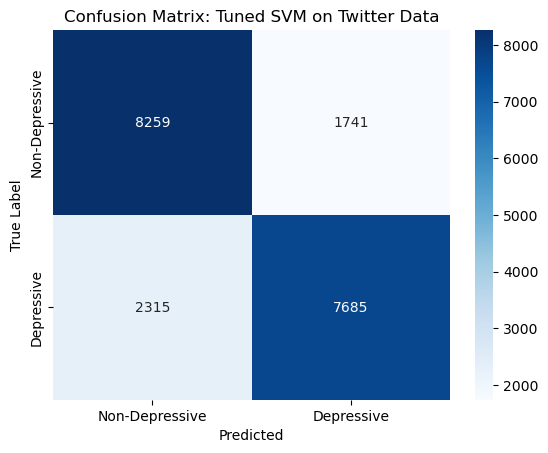

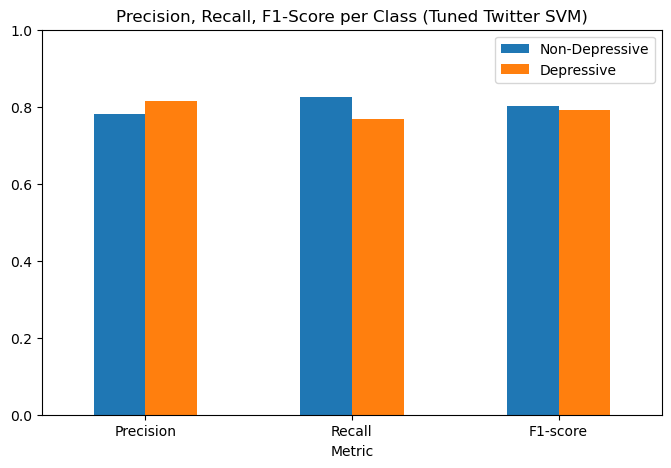

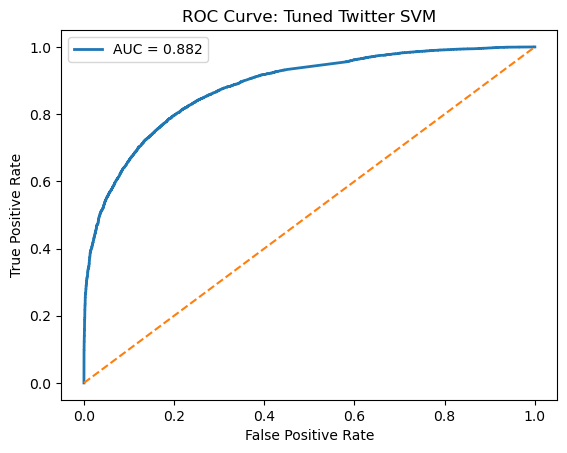

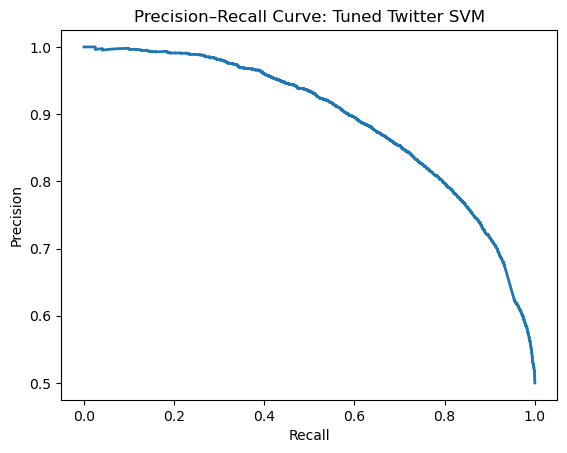

In [13]:
import pandas as pd
import joblib
import re
import string
from sklearn.svm import LinearSVC
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import (
    accuracy_score, classification_report, confusion_matrix,
    roc_curve, auc, precision_recall_curve, f1_score,
    precision_score, recall_score
)
import seaborn as sns
import matplotlib.pyplot as plt

# ------------------------------
# Load trained Reddit TF-IDF vectorizer
# ------------------------------
vectorizer = joblib.load("tfidf_reddit_vectorizer.pkl")

# ------------------------------
# Load and preprocess Twitter dataset
# ------------------------------
twitter_df = pd.read_csv("Mental-Health-Twitter.csv")

def preprocess_tweet(text):
    text = text.lower()
    text = re.sub(r"http\S+|www\S+", "", text)
    text = re.sub(r"@\w+", "", text)
    text = re.sub(r"#(\w+)", r"\1", text)
    text = re.sub(r"[^\w\s,]", "", text)
    text = re.sub(r'\d+', '', text)
    text = re.sub(r'\s+', ' ', text).strip()
    return text

twitter_df["clean_text"] = twitter_df["post_text"].astype(str).apply(preprocess_tweet)

# Transform Twitter text
X_twitter = vectorizer.transform(twitter_df["clean_text"])
y_twitter = twitter_df["label"]

# ------------------------------
# Hyperparameter tuning using GridSearchCV
# ------------------------------
param_grid = {
    "C": [0.01, 0.1, 1, 10],
    "class_weight": [None, "balanced"],
    "max_iter": [1000, 2000]
}

svm_model = LinearSVC()
grid_search = GridSearchCV(svm_model, param_grid, cv=5, verbose=1, n_jobs=-1)
grid_search.fit(X_twitter, y_twitter)

print("Best Parameters:", grid_search.best_params_)
best_svm = grid_search.best_estimator_

# Save tuned model
joblib.dump(best_svm, "svm_twitter_tuned.pkl")

# ------------------------------
# Evaluation
# ------------------------------
predicted = best_svm.predict(X_twitter)

print("\nAccuracy:", accuracy_score(y_twitter, predicted))
print("\nClassification Report:\n",
      classification_report(y_twitter, predicted, zero_division=0))

# ------------------------------
# Confusion Matrix
# ------------------------------
cm = confusion_matrix(y_twitter, predicted)
sns.heatmap(
    cm, annot=True, fmt='d', cmap='Blues',
    xticklabels=["Non-Depressive", "Depressive"],
    yticklabels=["Non-Depressive", "Depressive"]
)
plt.xlabel("Predicted")
plt.ylabel("True Label")
plt.title("Confusion Matrix: Tuned SVM on Twitter Data")
plt.show()

# ------------------------------
# Precision, Recall, F1 Bar Plot
# ------------------------------
precision = precision_score(y_twitter, predicted, average=None)
recall = recall_score(y_twitter, predicted, average=None)
f1 = f1_score(y_twitter, predicted, average=None)

metrics_df = pd.DataFrame({
    "Metric": ["Precision", "Recall", "F1-score"],
    "Non-Depressive": [precision[0], recall[0], f1[0]],
    "Depressive": [precision[1], recall[1], f1[1]]
}).set_index("Metric")

metrics_df.plot(kind='bar', figsize=(8, 5))
plt.title("Precision, Recall, F1-Score per Class (Tuned Twitter SVM)")
plt.ylim(0, 1)
plt.xticks(rotation=0)
plt.show()

# ------------------------------
# ROC Curve
# ------------------------------
# LinearSVC has no predict_proba -> use decision_function
decision_scores = best_svm.decision_function(X_twitter)
fpr, tpr, _ = roc_curve(y_twitter, decision_scores)
roc_auc = auc(fpr, tpr)

plt.plot(fpr, tpr, lw=2, label=f"AUC = {roc_auc:.3f}")
plt.plot([0, 1], [0, 1], linestyle='--')
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve: Tuned Twitter SVM")
plt.legend()
plt.show()

# ------------------------------
# Precision–Recall Curve
# ------------------------------
prec, rec, _ = precision_recall_curve(y_twitter, decision_scores)

plt.plot(rec, prec, lw=2)
plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Precision–Recall Curve: Tuned Twitter SVM")
plt.show()


[nltk_data] Downloading package stopwords to
[nltk_data]     C:\Users\Minhtu\AppData\Roaming\nltk_data...
[nltk_data]   Package stopwords is already up-to-date!
[nltk_data] Downloading package wordnet to
[nltk_data]     C:\Users\Minhtu\AppData\Roaming\nltk_data...
[nltk_data]   Package wordnet is already up-to-date!


Twitter train (20%): 4000
Twitter test (100%): 20000
Combined training dataset: 128444 samples

Running GridSearchCV...
Fitting 3 folds for each of 10 candidates, totalling 30 fits

Best Parameters: {'C': 0.01, 'class_weight': None}
Best CV Accuracy: 0.7127212606085691
GridSearchCV model saved as 'svm_reddit_twitter_mixed.pkl'

===================== Full Twitter Dataset EVALUATION =====================
Accuracy on Full Twitter Dataset: 0.5472

Classification Report:
               precision    recall  f1-score   support

           0       0.53      0.94      0.68     10000
           1       0.72      0.15      0.25     10000

    accuracy                           0.55     20000
   macro avg       0.62      0.55      0.46     20000
weighted avg       0.62      0.55      0.46     20000



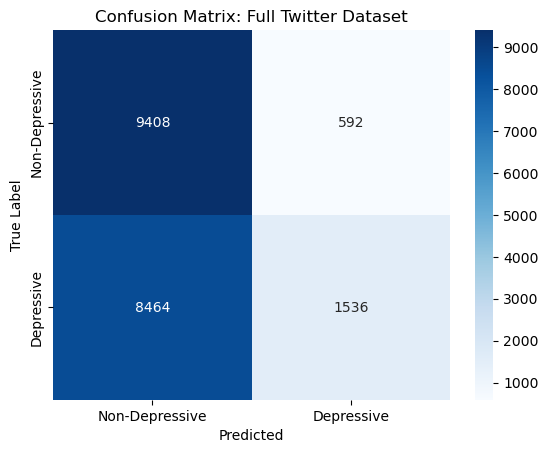

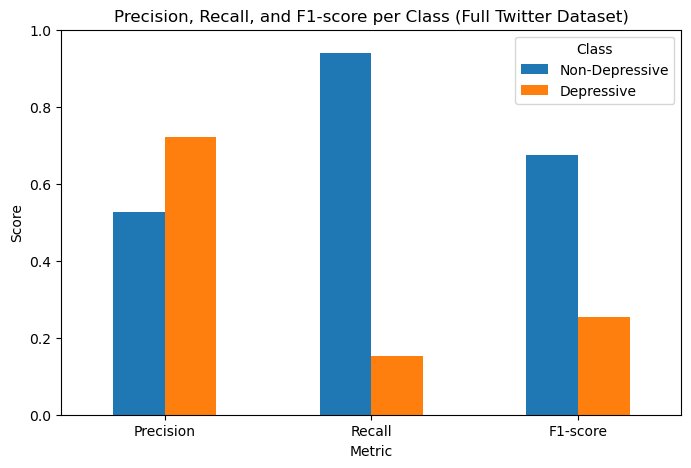

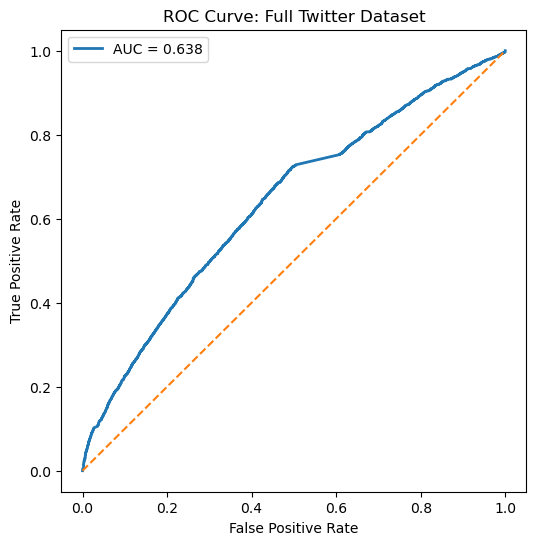

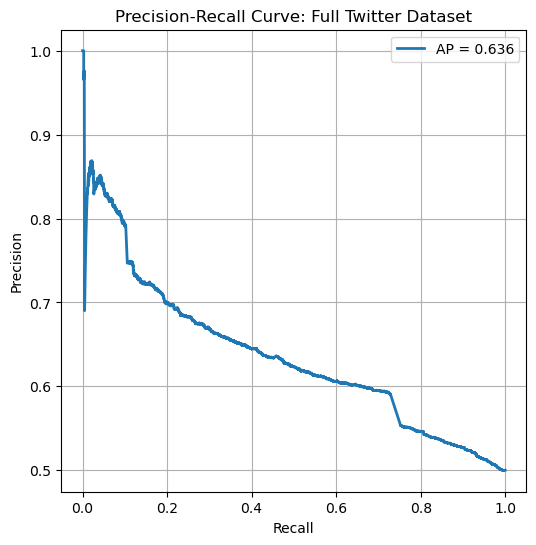


===================== Full Reddit Dataset EVALUATION =====================
Accuracy on Full Reddit Dataset: 0.9242

Classification Report:
               precision    recall  f1-score   support

           0       0.92      0.97      0.95     84907
           1       0.93      0.83      0.87     39537

    accuracy                           0.92    124444
   macro avg       0.93      0.90      0.91    124444
weighted avg       0.92      0.92      0.92    124444



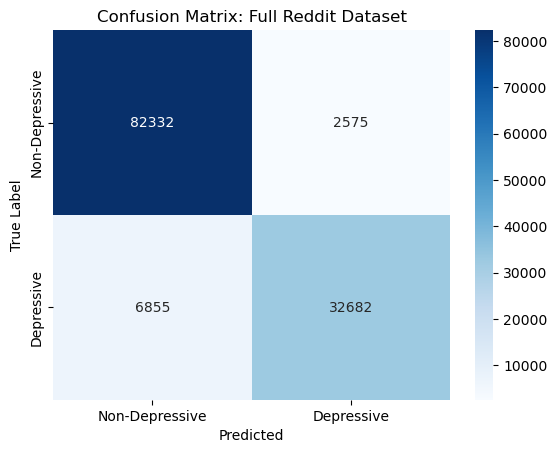

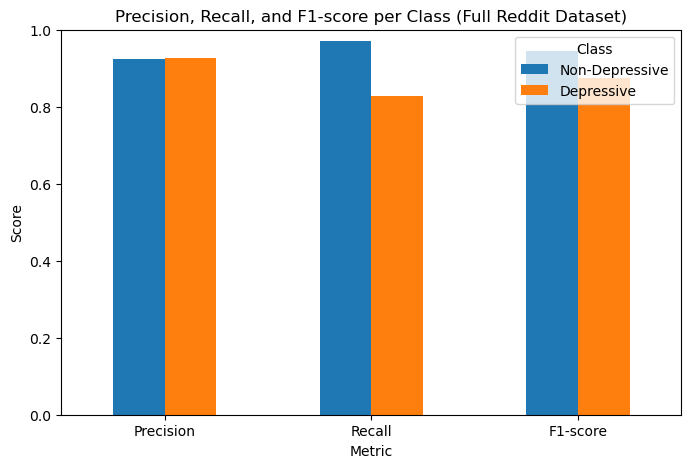

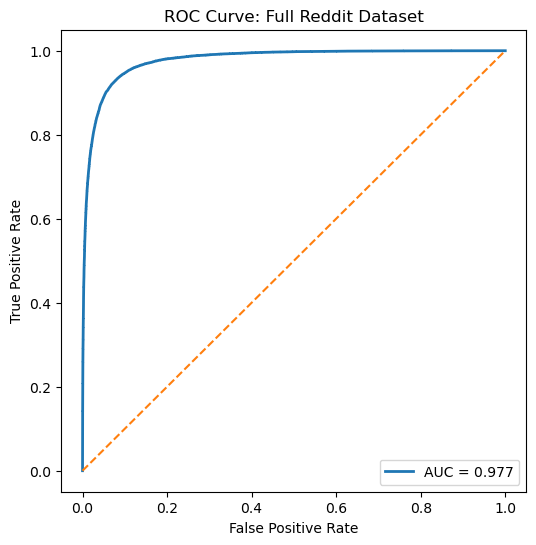

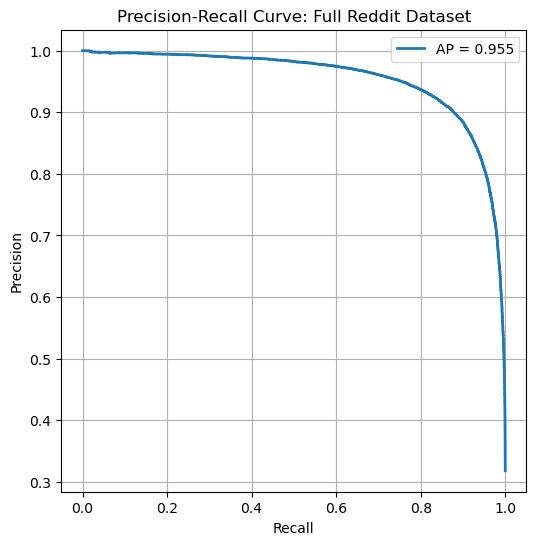

In [23]:
# ============================================================
#  TRAIN: Reddit + 20% Twitter | TEST: Full Twitter + Full Reddit
# ============================================================

import pandas as pd
import joblib
import re
import nltk
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np

from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.svm import LinearSVC
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.metrics import (
    accuracy_score, classification_report, confusion_matrix,
    roc_curve, auc, f1_score, precision_score, recall_score
)

# ------------------------------------------------------------
# 1. Load Reddit datasets
# ------------------------------------------------------------
reddit_datasets = {
    'addiction': pd.read_csv('addiction_2019_features_tfidf_256.csv'),
    'adhd': pd.read_csv('adhd_2019_features_tfidf_256.csv'),
    'alcoholism': pd.read_csv('alcoholism_2019_features_tfidf_256.csv'),
    'anxiety': pd.read_csv('anxiety_2019_features_tfidf_256.csv'),
    'jokes': pd.read_csv('jokes_2019_features_tfidf_256.csv'),
    'mentalhealth': pd.read_csv('mentalhealth_2019_features_tfidf_256.csv'),
    'conspiracy': pd.read_csv('conspiracy_2019_features_tfidf_256.csv'),
    'fitness': pd.read_csv('fitness_2019_features_tfidf_256.csv'),
    'meditation': pd.read_csv('meditation_2019_features_tfidf_256.csv'),
    'relationship': pd.read_csv('relationships_2019_features_tfidf_256.csv'),
    'teaching': pd.read_csv('teaching_2019_features_tfidf_256.csv'),
    'suicidewatch': pd.read_csv('suicidewatch_2019_features_tfidf_256.csv'),
}

for name, df in reddit_datasets.items():
    df['subreddit_name'] = name

combined_df = pd.concat(reddit_datasets.values(), ignore_index=True)

# Label Reddit data
depressive_subs = ['suicidewatch', 'mentalhealth', 'anxiety', 'addiction', 'alcoholism']
combined_df['label'] = combined_df['subreddit_name'].apply(lambda x: 1 if x in depressive_subs else 0)

# ------------------------------------------------------------
# 2. Text Preprocessing
# ------------------------------------------------------------
nltk.download('stopwords')
nltk.download('wordnet')

stop_words = set(stopwords.words('english'))
lemmatizer = WordNetLemmatizer()

def preprocess_text(text):
    text = str(text).lower()
    text = re.sub(r"http\S+|www\S+", "", text)
    text = re.sub(r"@\w+", "", text)
    text = re.sub(r"#(\w+)", r"\1", text)
    text = re.sub(r"[^a-z\s]", "", text)
    text = re.sub(r'\s+', ' ', text).strip()
    tokens = text.split()
    tokens = [lemmatizer.lemmatize(word) for word in tokens if word not in stop_words]
    return " ".join(tokens)

# ------------------------------------------------------------
# 3. Load and preprocess Twitter dataset
# ------------------------------------------------------------
twitter_df = pd.read_csv("Mental-Health-Twitter.csv")
twitter_df["clean_text"] = twitter_df["post_text"].astype(str).apply(preprocess_text)
twitter_df["label"] = twitter_df["label"].astype(int)

# ------------------------------------------------------------
# 4. Split Twitter dataset: 20% for training, 100% for testing
# ------------------------------------------------------------
twitter_train, _ = train_test_split(
    twitter_df,
    train_size=0.2,
    random_state=42,
    stratify=twitter_df["label"]
)

twitter_test = twitter_df.copy()

print(f"Twitter train (20%): {len(twitter_train)}")
print(f"Twitter test (100%): {len(twitter_test)}")

# ------------------------------------------------------------
# 5. Combine Reddit + 20% Twitter for training
# ------------------------------------------------------------
reddit_df = combined_df.copy()
reddit_df["clean_text"] = reddit_df["post"].astype(str).apply(preprocess_text)

train_mix = pd.concat([reddit_df, twitter_train], ignore_index=True)
print(f"Combined training dataset: {len(train_mix)} samples")

# ------------------------------------------------------------
# 6. TF-IDF Vectorization
# ------------------------------------------------------------
vectorizer = TfidfVectorizer(max_features=10000, ngram_range=(1, 2), sublinear_tf=True)
X_train = vectorizer.fit_transform(train_mix["clean_text"])
y_train = train_mix["label"]

joblib.dump(vectorizer, "tfidf_reddit_twitter_vectorizer.pkl")

# ============================================================
# 7. HYPERPARAMETER TUNING (GRIDSEARCHCV)
# ============================================================
param_grid = {
    "C": [0.01, 0.1, 1, 2, 5],
    "class_weight": [None, "balanced"]
}

grid_search = GridSearchCV(
    LinearSVC(max_iter=6000),
    param_grid,
    cv=3,
    scoring="accuracy",
    n_jobs=-1,
    verbose=1
)

print("\nRunning GridSearchCV...")
grid_search.fit(X_train, y_train)

print("\nBest Parameters:", grid_search.best_params_)
print("Best CV Accuracy:", grid_search.best_score_)

# Use best SVM model
svm = grid_search.best_estimator_

joblib.dump(svm, "svm_reddit_twitter_mixed.pkl")
print("GridSearchCV model saved as 'svm_reddit_twitter_mixed.pkl'")

# ============================================================
# 8. Evaluation Function (UNCHANGED)
# ============================================================

from sklearn.metrics import (
    accuracy_score, classification_report, confusion_matrix,
    roc_curve, auc, f1_score, precision_score, recall_score,
    precision_recall_curve, average_precision_score
)

def evaluate_model(name, df, vectorizer, model):
    print(f"\n===================== {name} EVALUATION =====================")
    X = vectorizer.transform(df["clean_text"])
    y_true = df["label"]
    y_pred = model.predict(X)

    acc = accuracy_score(y_true, y_pred)
    print(f"Accuracy on {name}: {acc:.4f}")
    print("\nClassification Report:\n", classification_report(y_true, y_pred, zero_division=0))

    # Confusion Matrix
    cm = confusion_matrix(y_true, y_pred)
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
                xticklabels=["Non-Depressive", "Depressive"],
                yticklabels=["Non-Depressive", "Depressive"])
    plt.title(f"Confusion Matrix: {name}")
    plt.xlabel("Predicted")
    plt.ylabel("True Label")
    plt.show()

    # Precision, Recall, F1 Plot
    f1 = f1_score(y_true, y_pred, average=None)
    precision = precision_score(y_true, y_pred, average=None)
    recall = recall_score(y_true, y_pred, average=None)

    metrics_df = pd.DataFrame({
        "Metric": ["Precision", "Recall", "F1-score"],
        "Non-Depressive": [precision[0], recall[0], f1[0]],
        "Depressive": [precision[1], recall[1], f1[1]]
    })

    metrics_df.set_index("Metric", inplace=True)
    metrics_df.plot(kind='bar', figsize=(8,5))
    plt.title(f"Precision, Recall, and F1-score per Class ({name})")
    plt.ylabel("Score")
    plt.ylim(0,1)
    plt.xticks(rotation=0)
    plt.legend(title="Class")
    plt.show()

    # ROC Curve
    y_score = model.decision_function(X)
    fpr, tpr, _ = roc_curve(y_true, y_score)
    roc_auc = auc(fpr, tpr)

    plt.figure(figsize=(6,6))
    plt.plot(fpr, tpr, lw=2, label=f'AUC = {roc_auc:.3f}')
    plt.plot([0,1], [0,1], linestyle='--')
    plt.xlabel('False Positive Rate')
    plt.ylabel('True Positive Rate')
    plt.title(f'ROC Curve: {name}')
    plt.legend()
    plt.show()

    # Precision-Recall Curve
    precision_curve, recall_curve, _ = precision_recall_curve(y_true, y_score)
    avg_precision = average_precision_score(y_true, y_score)

    plt.figure(figsize=(6,6))
    plt.plot(recall_curve, precision_curve, lw=2, label=f'AP = {avg_precision:.3f}')
    plt.xlabel('Recall')
    plt.ylabel('Precision')
    plt.title(f'Precision-Recall Curve: {name}')
    plt.legend()
    plt.grid()
    plt.show()

# ============================================================
# 9. Evaluate on BOTH Twitter and Reddit datasets
# ============================================================
vectorizer = joblib.load("tfidf_reddit_twitter_vectorizer.pkl")
svm = joblib.load("svm_reddit_twitter_mixed.pkl")

evaluate_model("Full Twitter Dataset", twitter_test, vectorizer, svm)
evaluate_model("Full Reddit Dataset", reddit_df, vectorizer, svm)


[nltk_data] Downloading package stopwords to
[nltk_data]     C:\Users\Minhtu\AppData\Roaming\nltk_data...
[nltk_data]   Package stopwords is already up-to-date!
[nltk_data] Downloading package wordnet to
[nltk_data]     C:\Users\Minhtu\AppData\Roaming\nltk_data...
[nltk_data]   Package wordnet is already up-to-date!


Twitter train (40%): 8000
Combined training dataset: 132444 samples

🔍 Running HalvingGridSearchCV...

n_iterations: 5
n_required_iterations: 5
n_possible_iterations: 5
min_resources_: 8277
max_resources_: 132444
aggressive_elimination: False
factor: 2
----------
iter: 0
n_candidates: 16
n_resources: 8277
Fitting 3 folds for each of 16 candidates, totalling 48 fits
----------
iter: 1
n_candidates: 8
n_resources: 16554
Fitting 3 folds for each of 8 candidates, totalling 24 fits
----------
iter: 2
n_candidates: 4
n_resources: 33108
Fitting 3 folds for each of 4 candidates, totalling 12 fits
----------
iter: 3
n_candidates: 2
n_resources: 66216
Fitting 3 folds for each of 2 candidates, totalling 6 fits
----------
iter: 4
n_candidates: 1
n_resources: 132432
Fitting 3 folds for each of 1 candidates, totalling 3 fits

✅ Best Parameters:
{'C': 0.1, 'class_weight': None, 'max_iter': 5000}

 Tuned model saved as 'svm_reddit_twitter_mixed_tuned.pkl'

===================== Full Twitter Dataset EV

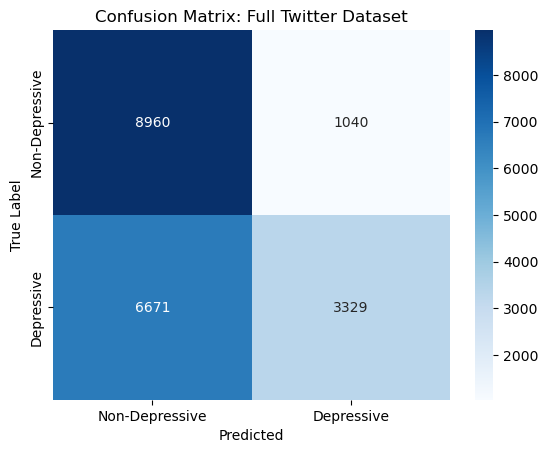

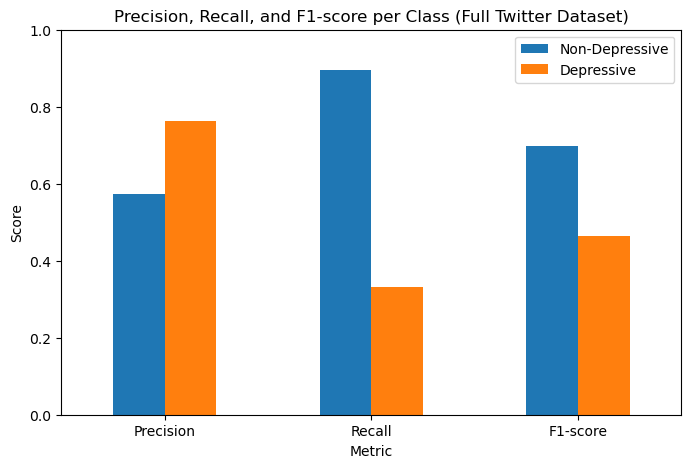

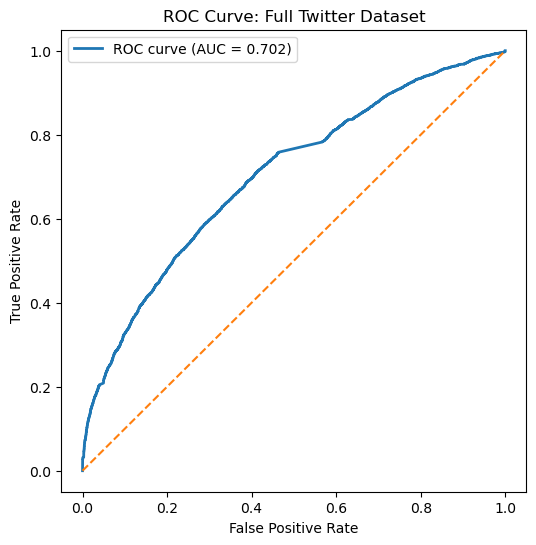

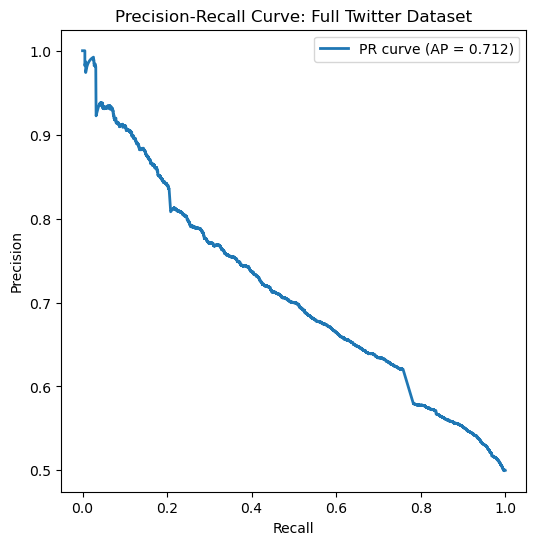


===================== Full Reddit Dataset EVALUATION =====================
Accuracy on Full Reddit Dataset: 0.9507

Classification Report:
               precision    recall  f1-score   support

           0       0.96      0.97      0.96     84907
           1       0.93      0.91      0.92     39537

    accuracy                           0.95    124444
   macro avg       0.95      0.94      0.94    124444
weighted avg       0.95      0.95      0.95    124444



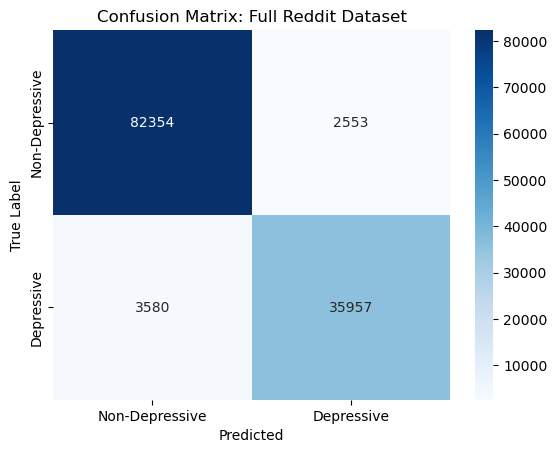

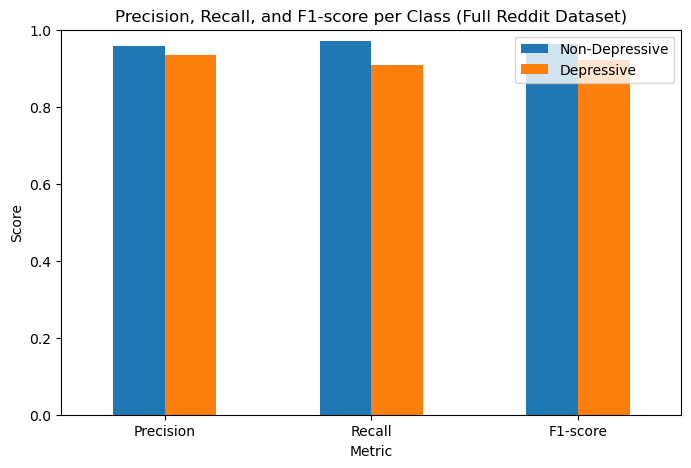

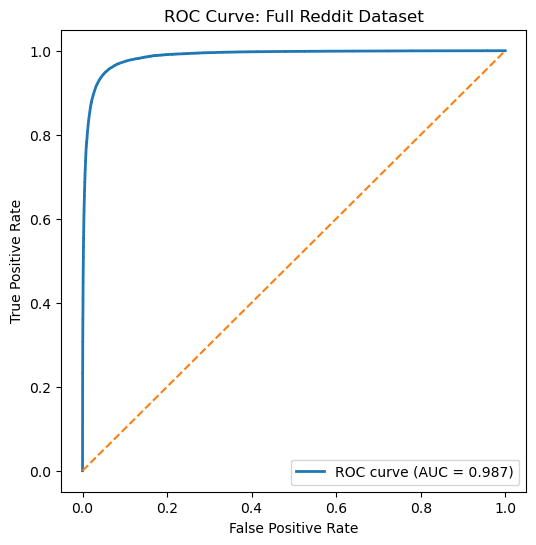

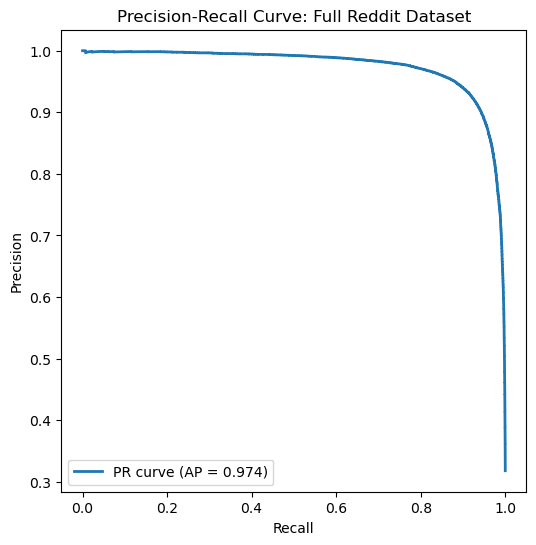

In [16]:
# ============================================================
#  TRAIN: Reddit + 40% Twitter | HYPERPARAM TUNING | TEST: Full Twitter + Full Reddit
# ============================================================

import pandas as pd
import joblib
import re
import nltk
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np

from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.svm import LinearSVC
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score, classification_report, confusion_matrix,
    roc_curve, auc, f1_score, precision_score, recall_score,
    precision_recall_curve, average_precision_score
)

# ------------------------------------------------------------
# 1. Load Reddit datasets
# ------------------------------------------------------------
reddit_datasets = {
    'addiction': pd.read_csv('addiction_2019_features_tfidf_256.csv'),
    'adhd': pd.read_csv('adhd_2019_features_tfidf_256.csv'),
    'alcoholism': pd.read_csv('alcoholism_2019_features_tfidf_256.csv'),
    'anxiety': pd.read_csv('anxiety_2019_features_tfidf_256.csv'),
    'jokes': pd.read_csv('jokes_2019_features_tfidf_256.csv'),
    'mentalhealth': pd.read_csv('mentalhealth_2019_features_tfidf_256.csv'),
    'conspiracy': pd.read_csv('conspiracy_2019_features_tfidf_256.csv'),
    'fitness': pd.read_csv('fitness_2019_features_tfidf_256.csv'),
    'meditation': pd.read_csv('meditation_2019_features_tfidf_256.csv'),
    'relationship': pd.read_csv('relationships_2019_features_tfidf_256.csv'),
    'teaching': pd.read_csv('teaching_2019_features_tfidf_256.csv'),
    'suicidewatch': pd.read_csv('suicidewatch_2019_features_tfidf_256.csv'),
}

for name, df in reddit_datasets.items():
    df['subreddit_name'] = name

combined_df = pd.concat(reddit_datasets.values(), ignore_index=True)

# Label Reddit data
depressive_subs = ['suicidewatch', 'mentalhealth', 'anxiety', 'addiction', 'alcoholism']
combined_df['label'] = combined_df['subreddit_name'].apply(lambda x: 1 if x in depressive_subs else 0)

# ------------------------------------------------------------
# 2. Text Preprocessing
# ------------------------------------------------------------
nltk.download('stopwords')
nltk.download('wordnet')

stop_words = set(stopwords.words('english'))
lemmatizer = WordNetLemmatizer()

def preprocess_text(text):
    text = str(text).lower()
    text = re.sub(r"http\S+|www\S+", "", text)
    text = re.sub(r"@\w+", "", text)
    text = re.sub(r"#(\w+)", r"\1", text)
    text = re.sub(r"[^a-z\s]", "", text)
    text = re.sub(r'\s+', ' ', text).strip()
    tokens = text.split()
    tokens = [lemmatizer.lemmatize(word) for word in tokens if word not in stop_words]
    return " ".join(tokens)

# ------------------------------------------------------------
# 3. Load and preprocess Twitter dataset
# ------------------------------------------------------------
twitter_df = pd.read_csv("Mental-Health-Twitter.csv")
twitter_df["clean_text"] = twitter_df["post_text"].astype(str).apply(preprocess_text)
twitter_df["label"] = twitter_df["label"].astype(int)

# ------------------------------------------------------------
# 4. Split Twitter dataset: 40% for training
# ------------------------------------------------------------
twitter_train, _ = train_test_split(
    twitter_df,
    train_size=0.4,
    random_state=42,
    stratify=twitter_df["label"]
)

twitter_test = twitter_df.copy()

print(f"Twitter train (40%): {len(twitter_train)}")

# ------------------------------------------------------------
# 5. Combine Reddit + 40% Twitter for training
# ------------------------------------------------------------
reddit_df = combined_df.copy()
reddit_df["clean_text"] = reddit_df["post"].astype(str).apply(preprocess_text)

train_mix = pd.concat([reddit_df, twitter_train], ignore_index=True)
print(f"Combined training dataset: {len(train_mix)} samples")

# ------------------------------------------------------------
# 6. TF-IDF Vectorization
# ------------------------------------------------------------
vectorizer = TfidfVectorizer(max_features=10000, ngram_range=(1, 2), sublinear_tf=True)
X_train = vectorizer.fit_transform(train_mix["clean_text"])
y_train = train_mix["label"]

joblib.dump(vectorizer, "tfidf_reddit_twitter_vectorizer.pkl")

# ============================================================
#  HYPERPARAMETER TUNING — HALVING GRID SEARCH
# ============================================================

from sklearn.experimental import enable_halving_search_cv
from sklearn.model_selection import HalvingGridSearchCV

param_grid = {
    "C": [0.01, 0.1, 1, 10],
    "class_weight": [None, "balanced"],
    "max_iter": [2000, 5000]
}

halving_search = HalvingGridSearchCV(
    estimator=LinearSVC(),
    param_grid=param_grid,
    factor=2,
    resource='n_samples',
    max_resources='auto',
    cv=3,
    scoring='accuracy',
    verbose=2,
    n_jobs=-1
)

print("\n🔍 Running HalvingGridSearchCV...\n")
halving_search.fit(X_train, y_train)

print("\n✅ Best Parameters:")
print(halving_search.best_params_)

best_svm = halving_search.best_estimator_

joblib.dump(best_svm, "svm_reddit_twitter_mixed_tuned.pkl")
print("\n Tuned model saved as 'svm_reddit_twitter_mixed_tuned.pkl'")

# ------------------------------------------------------------
# 8. Evaluation Function
# ------------------------------------------------------------
def evaluate_model(name, df, vectorizer, model):
    print(f"\n===================== {name} EVALUATION =====================")
    X = vectorizer.transform(df["clean_text"])
    y_true = df["label"]
    y_pred = model.predict(X)

    acc = accuracy_score(y_true, y_pred)
    print(f"Accuracy on {name}: {acc:.4f}")
    print("\nClassification Report:\n", classification_report(y_true, y_pred, zero_division=0))

    # Confusion Matrix
    cm = confusion_matrix(y_true, y_pred)
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
                xticklabels=["Non-Depressive", "Depressive"],
                yticklabels=["Non-Depressive", "Depressive"])
    plt.title(f"Confusion Matrix: {name}")
    plt.xlabel("Predicted")
    plt.ylabel("True Label")
    plt.show()

    # Metrics bar chart
    f1 = f1_score(y_true, y_pred, average=None)
    precision = precision_score(y_true, y_pred, average=None)
    recall = recall_score(y_true, y_pred, average=None)

    metrics_df = pd.DataFrame({
        "Metric": ["Precision", "Recall", "F1-score"],
        "Non-Depressive": [precision[0], recall[0], f1[0]],
        "Depressive": [precision[1], recall[1], f1[1]]
    })

    metrics_df.set_index("Metric", inplace=True)
    metrics_df.plot(kind='bar', figsize=(8, 5))
    plt.title(f"Precision, Recall, and F1-score per Class ({name})")
    plt.ylabel("Score")
    plt.ylim(0, 1)
    plt.xticks(rotation=0)
    plt.show()

    # ROC Curve
    y_score = model.decision_function(X)
    fpr, tpr, _ = roc_curve(y_true, y_score)
    roc_auc = auc(fpr, tpr)

    plt.figure(figsize=(6, 6))
    plt.plot(fpr, tpr, lw=2, label=f'ROC curve (AUC = {roc_auc:.3f})')
    plt.plot([0, 1], [0, 1], linestyle='--')
    plt.xlabel('False Positive Rate')
    plt.ylabel('True Positive Rate')
    plt.title(f'ROC Curve: {name}')
    plt.legend()
    plt.show()

    # Precision-Recall Curve
    precision_curve, recall_curve, _ = precision_recall_curve(y_true, y_score)
    avg_precision = average_precision_score(y_true, y_score)

    plt.figure(figsize=(6, 6))
    plt.plot(recall_curve, precision_curve, lw=2,
             label=f'PR curve (AP = {avg_precision:.3f})')
    plt.xlabel('Recall')
    plt.ylabel('Precision')
    plt.title(f'Precision-Recall Curve: {name}')
    plt.legend()
    plt.show()

# ------------------------------------------------------------
# 9. Run Evaluation on Both Datasets
# ------------------------------------------------------------
vectorizer = joblib.load("tfidf_reddit_twitter_vectorizer.pkl")
svm = joblib.load("svm_reddit_twitter_mixed_tuned.pkl")

evaluate_model("Full Twitter Dataset", twitter_test, vectorizer, svm)
evaluate_model("Full Reddit Dataset", reddit_df, vectorizer, svm)


[nltk_data] Downloading package stopwords to
[nltk_data]     C:\Users\Minhtu\AppData\Roaming\nltk_data...
[nltk_data]   Package stopwords is already up-to-date!
[nltk_data] Downloading package wordnet to
[nltk_data]     C:\Users\Minhtu\AppData\Roaming\nltk_data...
[nltk_data]   Package wordnet is already up-to-date!


Loaded Twitter dataset: (20000, 12)
label
1    10000
0    10000
Name: count, dtype: int64
TF-IDF vectorizer saved as 'tfidf_twitter_full_vectorizer.pkl'
Model saved as 'svm_twitter_full.pkl'

Accuracy: 0.9196

Classification Report:
               precision    recall  f1-score   support

           0       0.91      0.93      0.92     10000
           1       0.92      0.91      0.92     10000

    accuracy                           0.92     20000
   macro avg       0.92      0.92      0.92     20000
weighted avg       0.92      0.92      0.92     20000



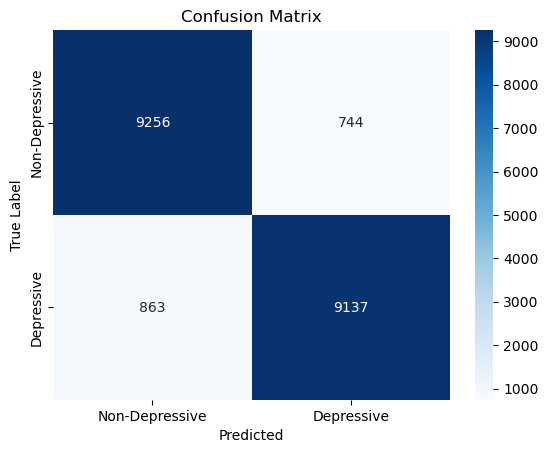

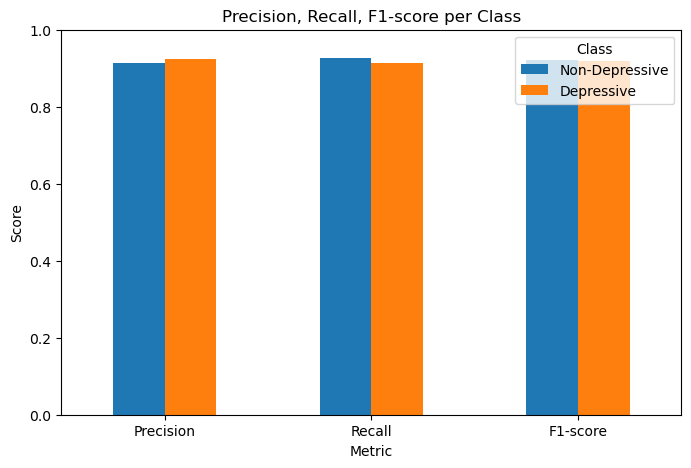

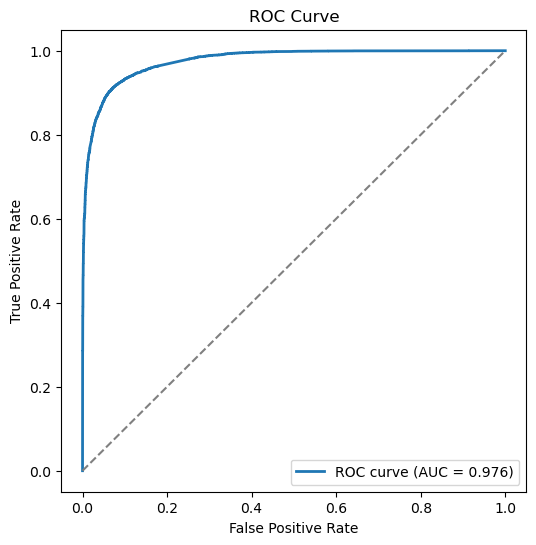

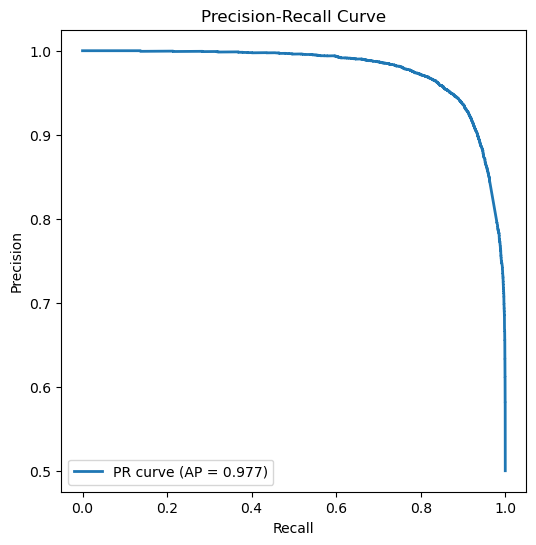

In [21]:
# ============================================================
#  TRAIN + EVALUATE: Full Twitter Dataset with Plots
# ============================================================

import pandas as pd
import joblib
import re
import nltk
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np

from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.svm import LinearSVC
from sklearn.metrics import (
    accuracy_score, classification_report, confusion_matrix,
    f1_score, precision_score, recall_score,
    roc_curve, auc, precision_recall_curve, average_precision_score
)

# ------------------------------------------------------------
# 1. Text Preprocessing
# ------------------------------------------------------------
nltk.download('stopwords')
nltk.download('wordnet')

stop_words = set(stopwords.words('english'))
lemmatizer = WordNetLemmatizer()

def preprocess_text(text):
    text = str(text).lower()
    text = re.sub(r"http\S+|www\S+", "", text)
    text = re.sub(r"@\w+", "", text)
    text = re.sub(r"#(\w+)", r"\1", text)
    text = re.sub(r"[^a-z\s]", "", text)
    text = re.sub(r'\s+', ' ', text).strip()
    tokens = text.split()
    tokens = [lemmatizer.lemmatize(word) for word in tokens if word not in stop_words]
    return " ".join(tokens)

# ------------------------------------------------------------
# 2. Load and preprocess Twitter dataset
# ------------------------------------------------------------
twitter_df = pd.read_csv("Mental-Health-Twitter.csv")
twitter_df["clean_text"] = twitter_df["post_text"].astype(str).apply(preprocess_text)
twitter_df["label"] = twitter_df["label"].astype(int)

print("Loaded Twitter dataset:", twitter_df.shape)
print(twitter_df["label"].value_counts())

# ------------------------------------------------------------
# 3. TF-IDF Vectorization
# ------------------------------------------------------------
vectorizer = TfidfVectorizer(max_features=10000, ngram_range=(1,2), sublinear_tf=True)
X = vectorizer.fit_transform(twitter_df["clean_text"])
y = twitter_df["label"]

joblib.dump(vectorizer, "tfidf_twitter_full_vectorizer.pkl")
print("TF-IDF vectorizer saved as 'tfidf_twitter_full_vectorizer.pkl'")

# ------------------------------------------------------------
# 4. Train SVM
# ------------------------------------------------------------
svm = LinearSVC(C=1.0, class_weight='balanced', max_iter=5000)
svm.fit(X, y)

joblib.dump(svm, "svm_twitter_full.pkl")
print("Model saved as 'svm_twitter_full.pkl'")

# ------------------------------------------------------------
# 5. Evaluation Function with Plots
# ------------------------------------------------------------
def evaluate_model(X, y, model):
    y_pred = model.predict(X)

    # Accuracy and classification report
    accuracy = accuracy_score(y, y_pred)
    print(f"\nAccuracy: {accuracy:.4f}")
    print("\nClassification Report:\n", classification_report(y, y_pred, zero_division=0))

    # Confusion Matrix
    cm = confusion_matrix(y, y_pred)
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
                xticklabels=["Non-Depressive", "Depressive"],
                yticklabels=["Non-Depressive", "Depressive"])
    plt.title("Confusion Matrix")
    plt.xlabel("Predicted")
    plt.ylabel("True Label")
    plt.show()

    # Precision, Recall, F1 per class
    precision = precision_score(y, y_pred, average=None)
    recall = recall_score(y, y_pred, average=None)
    f1 = f1_score(y, y_pred, average=None)

    metrics_df = pd.DataFrame({
        "Metric": ["Precision", "Recall", "F1-score"],
        "Non-Depressive": [precision[0], recall[0], f1[0]],
        "Depressive": [precision[1], recall[1], f1[1]]
    }).set_index("Metric")

    metrics_df.plot(kind='bar', figsize=(8,5))
    plt.title("Precision, Recall, F1-score per Class")
    plt.ylim(0,1)
    plt.ylabel("Score")
    plt.xticks(rotation=0)
    plt.legend(title="Class")
    plt.show()

    # ROC Curve
    y_score = model.decision_function(X)
    fpr, tpr, _ = roc_curve(y, y_score)
    roc_auc = auc(fpr, tpr)
    plt.figure(figsize=(6,6))
    plt.plot(fpr, tpr, lw=2, label=f'ROC curve (AUC = {roc_auc:.3f})')
    plt.plot([0,1], [0,1], linestyle='--', color='gray')
    plt.xlabel("False Positive Rate")
    plt.ylabel("True Positive Rate")
    plt.title("ROC Curve")
    plt.legend()
    plt.show()

    # Precision-Recall Curve
    precision_curve, recall_curve, _ = precision_recall_curve(y, y_score)
    avg_precision = average_precision_score(y, y_score)
    plt.figure(figsize=(6,6))
    plt.plot(recall_curve, precision_curve, lw=2,
             label=f'PR curve (AP = {avg_precision:.3f})')
    plt.xlabel("Recall")
    plt.ylabel("Precision")
    plt.title("Precision-Recall Curve")
    plt.legend()
    plt.show()

# ------------------------------------------------------------
# 6. Run Evaluation
# ------------------------------------------------------------
evaluate_model(X, y, svm)


Loaded TF-IDF vectorizer.


[nltk_data] Downloading package stopwords to
[nltk_data]     C:\Users\Minhtu\AppData\Roaming\nltk_data...
[nltk_data]   Package stopwords is already up-to-date!
[nltk_data] Downloading package wordnet to
[nltk_data]     C:\Users\Minhtu\AppData\Roaming\nltk_data...
[nltk_data]   Package wordnet is already up-to-date!


Preprocessing Reddit text...

🔍 Running GridSearchCV on Reddit dataset...

Fitting 3 folds for each of 16 candidates, totalling 48 fits

✅ Best Parameters Found:
{'C': 0.01, 'class_weight': None, 'max_iter': 2000}
Tuned SVM saved as 'svm_twitter_reddit_tuned.pkl'

Accuracy on Reddit Dataset: 0.9118

Classification Report:
               precision    recall  f1-score   support

           0       0.91      0.96      0.94     84907
           1       0.91      0.80      0.85     39537

    accuracy                           0.91    124444
   macro avg       0.91      0.88      0.89    124444
weighted avg       0.91      0.91      0.91    124444



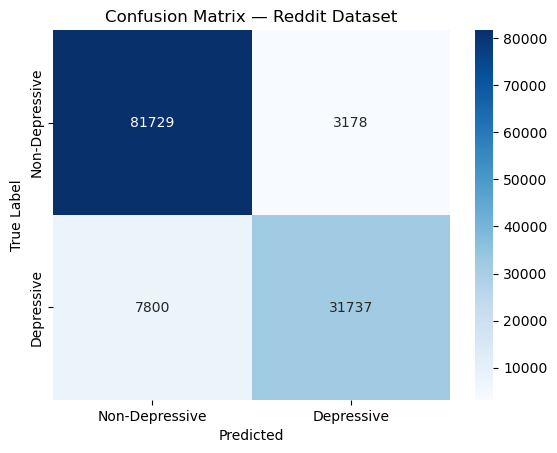

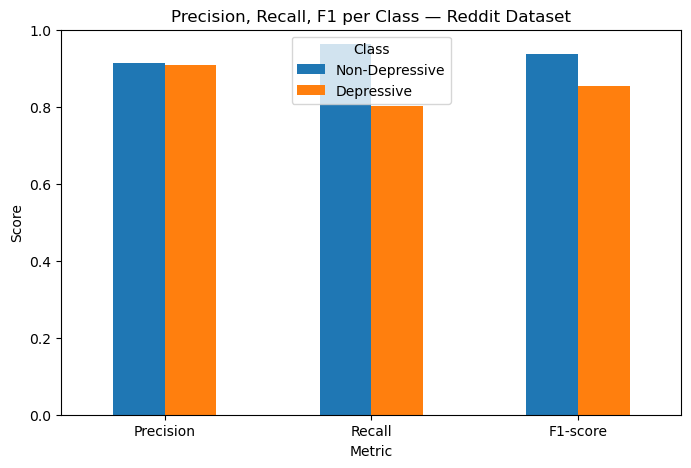

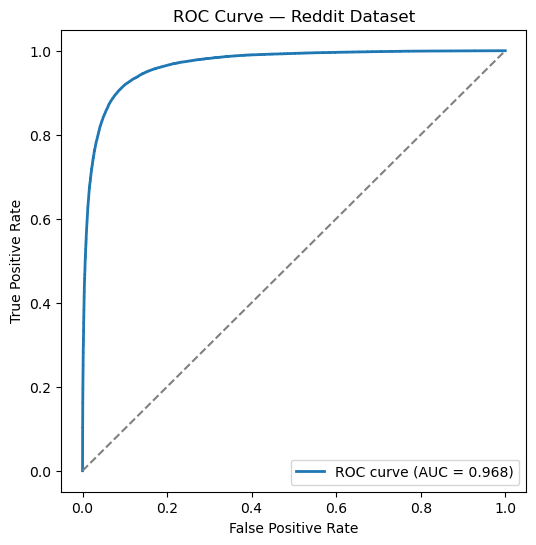

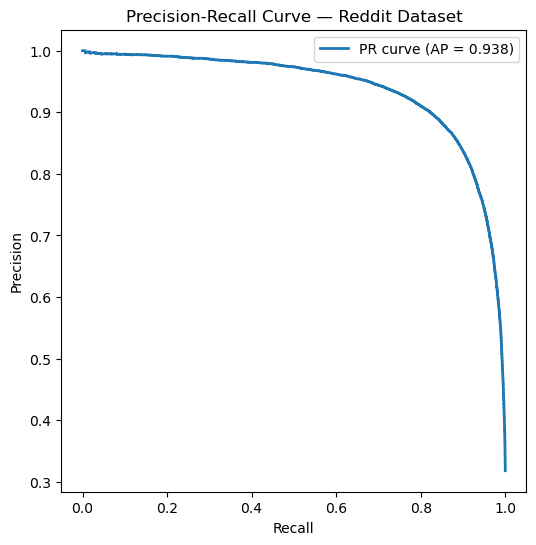


Accuracy per subreddit:
  addiction       → 0.5919
  adhd            → 0.8946
  alcoholism      → 0.6571
  anxiety         → 0.8325
  conspiracy      → 0.9869
  fitness         → 0.9923
  jokes           → 0.9908
  meditation      → 0.9036
  mentalhealth    → 0.7244
  relationship    → 0.9440
  suicidewatch    → 0.8544
  teaching        → 0.9601


In [22]:
# ============================================================
#  TEST TWITTER-TRAINED MODEL ON REDDIT DATASET WITH HYPERPARAMETER TUNING
# ============================================================

import pandas as pd
import joblib
import re
import nltk
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np

from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer
from sklearn.svm import LinearSVC
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import (
    accuracy_score, classification_report, confusion_matrix,
    f1_score, precision_score, recall_score,
    roc_curve, auc, precision_recall_curve, average_precision_score
)

# ------------------------------------------------------------
# 1. Load saved vectorizer
# ------------------------------------------------------------
vectorizer = joblib.load("tfidf_twitter_full_vectorizer.pkl")
print("Loaded TF-IDF vectorizer.")

# ------------------------------------------------------------
# 2. Text preprocessing
# ------------------------------------------------------------
nltk.download('stopwords')
nltk.download('wordnet')

stop_words = set(stopwords.words('english'))
lemmatizer = WordNetLemmatizer()

def preprocess_text(text):
    text = str(text).lower()
    text = re.sub(r"http\S+|www\S+", "", text)
    text = re.sub(r"@\w+", "", text)
    text = re.sub(r"#(\w+)", r"\1", text)
    text = re.sub(r"[^a-z\s]", "", text)
    text = re.sub(r'\s+', ' ', text).strip()
    tokens = text.split()
    tokens = [lemmatizer.lemmatize(word) for word in tokens if word not in stop_words]
    return " ".join(tokens)

# ------------------------------------------------------------
# 3. Load Reddit datasets
# ------------------------------------------------------------
reddit_datasets = {
    'addiction': pd.read_csv('addiction_2019_features_tfidf_256.csv'),
    'adhd': pd.read_csv('adhd_2019_features_tfidf_256.csv'),
    'alcoholism': pd.read_csv('alcoholism_2019_features_tfidf_256.csv'),
    'anxiety': pd.read_csv('anxiety_2019_features_tfidf_256.csv'),
    'jokes': pd.read_csv('jokes_2019_features_tfidf_256.csv'),
    'mentalhealth': pd.read_csv('mentalhealth_2019_features_tfidf_256.csv'),
    'conspiracy': pd.read_csv('conspiracy_2019_features_tfidf_256.csv'),
    'fitness': pd.read_csv('fitness_2019_features_tfidf_256.csv'),
    'meditation': pd.read_csv('meditation_2019_features_tfidf_256.csv'),
    'relationship': pd.read_csv('relationships_2019_features_tfidf_256.csv'),
    'teaching': pd.read_csv('teaching_2019_features_tfidf_256.csv'),
    'suicidewatch': pd.read_csv('suicidewatch_2019_features_tfidf_256.csv'),
}

for name, df in reddit_datasets.items():
    df['subreddit_name'] = name

combined_df = pd.concat(reddit_datasets.values(), ignore_index=True)

# ------------------------------------------------------------
# 4. Preprocess Reddit posts and label
# ------------------------------------------------------------
print("Preprocessing Reddit text...")
combined_df['clean_post'] = combined_df['post'].astype(str).apply(preprocess_text)
depressive_subs = ['suicidewatch', 'mentalhealth', 'anxiety', 'addiction', 'alcoholism']
combined_df['label'] = combined_df['subreddit_name'].apply(lambda x: 1 if x in depressive_subs else 0)

# Transform Reddit posts using Twitter vectorizer
X_test = vectorizer.transform(combined_df['clean_post'])
y_test = combined_df['label']

# ------------------------------------------------------------
# 5. Hyperparameter tuning on Reddit dataset
# ------------------------------------------------------------
param_grid = {
    "C": [0.01, 0.1, 1, 10],
    "class_weight": [None, "balanced"],
    "max_iter": [2000, 5000]
}

grid_search = GridSearchCV(
    estimator=LinearSVC(),
    param_grid=param_grid,
    cv=3,
    scoring='accuracy',
    verbose=2,
    n_jobs=-1
)

print("\n🔍 Running GridSearchCV on Reddit dataset...\n")
grid_search.fit(X_test, y_test)

print("\n✅ Best Parameters Found:")
print(grid_search.best_params_)

best_svm = grid_search.best_estimator_
joblib.dump(best_svm, "svm_twitter_reddit_tuned.pkl")
print("Tuned SVM saved as 'svm_twitter_reddit_tuned.pkl'")

# ------------------------------------------------------------
# 6. Evaluation function with plots
# ------------------------------------------------------------
def evaluate_model(X, y, model, dataset_name="Dataset"):
    y_pred = model.predict(X)

    # Accuracy and classification report
    accuracy = accuracy_score(y, y_pred)
    print(f"\nAccuracy on {dataset_name}: {accuracy:.4f}")
    print("\nClassification Report:\n", classification_report(y, y_pred, zero_division=0))

    # Confusion matrix
    cm = confusion_matrix(y, y_pred)
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
                xticklabels=["Non-Depressive", "Depressive"],
                yticklabels=["Non-Depressive", "Depressive"])
    plt.title(f"Confusion Matrix — {dataset_name}")
    plt.xlabel("Predicted")
    plt.ylabel("True Label")
    plt.show()

    # Precision, Recall, F1
    precision = precision_score(y, y_pred, average=None)
    recall = recall_score(y, y_pred, average=None)
    f1 = f1_score(y, y_pred, average=None)
    metrics_df = pd.DataFrame({
        "Metric": ["Precision", "Recall", "F1-score"],
        "Non-Depressive": [precision[0], recall[0], f1[0]],
        "Depressive": [precision[1], recall[1], f1[1]]
    }).set_index("Metric")
    metrics_df.plot(kind='bar', figsize=(8,5))
    plt.title(f"Precision, Recall, F1 per Class — {dataset_name}")
    plt.ylim(0,1)
    plt.ylabel("Score")
    plt.xticks(rotation=0)
    plt.legend(title="Class")
    plt.show()

    # ROC Curve
    y_score = model.decision_function(X)
    fpr, tpr, _ = roc_curve(y, y_score)
    roc_auc = auc(fpr, tpr)
    plt.figure(figsize=(6,6))
    plt.plot(fpr, tpr, lw=2, label=f'ROC curve (AUC = {roc_auc:.3f})')
    plt.plot([0,1], [0,1], linestyle='--', color='gray')
    plt.xlabel("False Positive Rate")
    plt.ylabel("True Positive Rate")
    plt.title(f"ROC Curve — {dataset_name}")
    plt.legend()
    plt.show()

    # Precision-Recall Curve
    precision_curve, recall_curve, _ = precision_recall_curve(y, y_score)
    avg_precision = average_precision_score(y, y_score)
    plt.figure(figsize=(6,6))
    plt.plot(recall_curve, precision_curve, lw=2,
             label=f'PR curve (AP = {avg_precision:.3f})')
    plt.xlabel("Recall")
    plt.ylabel("Precision")
    plt.title(f"Precision-Recall Curve — {dataset_name}")
    plt.legend()
    plt.show()

# ------------------------------------------------------------
# 7. Run evaluation
# ------------------------------------------------------------
evaluate_model(X_test, y_test, best_svm, dataset_name="Reddit Dataset")

# ------------------------------------------------------------
# 8. Per-subreddit accuracy
# ------------------------------------------------------------
print("\nAccuracy per subreddit:")
for name, group in combined_df.groupby('subreddit_name'):
    acc = accuracy_score(group['label'], best_svm.predict(X_test[group.index]))
    print(f"  {name:<15} → {acc:.4f}")
